In [1]:
import sys
import pandas as pd

import numpy as np
import mvEEG.mvEEG as mvEEG
import mne_bids


import matplotlib.pyplot as plt
plt.rcParams["svg.fonttype"] = "none"

import seaborn as sns 
from os import path

from glob import glob
import json
import tqdm.auto as ta


%load_ext autoreload
%autoreload 2

In [3]:
ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan2"
bad_epochs = (
    {  # epochs which didn't align with eye tracking for one reason or another, and were excluded during preprocessing
        "05": [737, 739, 740, 741, 745, 746],
        "21": [649, 650, 651, 652],
    }
)

bad_blocks = {
    # blocks for which participants admitted they were confused about the task (normally at the start, or first switch to the other task)
    "17": [6],  # first attention block
    "22": [6, 7, 8, 9],  # was doing SS0 incorrectly for the first few WM blocks
    "32": [6],  # first WM block
}

# participant who came back for a second session. We are going to combine the two sessions.
split_sess_subs = {"22": "34"}

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans={},
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1200],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

# Performance on main tasks (WM & Spatial Attention)

In [4]:
def load_behavioral_data(wrangl, isub):
    # get all behavioral files for this subject
    basepath = "/".join(
        str(wrangl.bids_path.copy().update(subject=wrangl.subs[isub], datatype="beh").fpath).split("/")[:-1]
    )
    beh_files = glob(path.join(basepath, "*_data_block*.csv"))

    # load and concatenate behavioral data
    beh = pd.DataFrame()
    for f in beh_files:
        df_block = pd.read_csv(f)
        beh = pd.concat([beh, df_block], axis=0)

    # sort by Block and Trial to ensure proper alignment with EEG epochs
    beh = beh.sort_values(by=["Block", "Trial"]).reset_index(drop=True)

    beh = beh.loc[~(beh.REJ == 1)].reset_index(
        drop=True
    )  # remove real time eye tracking rejects, which aren't in the EEG
    beh = beh.drop(bad_epochs.get(wrangl.subs[isub], [])).reset_index(
        drop=True
    )  # drop bad epochs due to sync errors with eye tracking
    beh = beh.loc[~wrangl.artifacts[isub], :].reset_index(
        drop=True
    )  # drop epochs marked as artifacts during preprocessing

    if wrangl.subs[isub] == "13":
        beh["Subject"] = 13  # fix subject number for sub-13, which was mis-labeled as sub-12 in behavioral data

    return beh


# helper functions to compute K and accuracy by set size for the WM task
def compute_k(accs, changes, ss):
    HR = np.sum(accs * changes) / np.sum(changes)
    FA = np.sum((~accs) * (~changes)) / np.sum(~changes)
    return ss * (HR - FA)


def get_k_by_ss(beh_mem):
    beh_mem.loc[:, "n_targets"] = beh_mem.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_mem.n_targets.unique())
    k_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_mem.query(f"n_targets=={ss}")
        # get accuracy and change trial info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        changes = np.array([c == "True" for c in curr_beh["change"].astype(str).values])
        k_by_ss[int(ss)] = compute_k(accs, changes, int(ss))
    return k_by_ss


def get_WM_acc_by_ss(beh_mem):
    beh_mem.loc[:, "n_targets"] = beh_mem.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_mem.n_targets.unique())
    acc_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_mem.query(f"n_targets=={ss}")
        # get accuracy and change trial info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        acc_by_ss[int(ss)] = np.mean(accs)
    return acc_by_ss


# helper functions to compute attention probe accuracies and false alarms
def compute_probe_misses(resps):
    n_misses = np.sum(resps == "space")
    n_total = len(resps)
    return n_misses / n_total


def get_probe_misses_by_ss(beh_attn):
    beh_attn = beh_attn[
        beh_attn.relevant_num.notna()
    ].copy()  # keep only trials where a probe number was presented, regardless of during delay or at test (SS0)
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    miss_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        resps = curr_beh.RESP.values
        miss_by_ss[int(ss)] = compute_probe_misses(resps)
    return miss_by_ss


def get_probe_accs_by_ss(beh_attn):
    beh_attn = beh_attn[
        beh_attn.relevant_num.notna()
    ].copy()  # keep only trials where a probe number was presented, regardless of during delay or at test (SS0)
    beh_attn = beh_attn.query("RESP != 'space'")  # keep only trials where subject made a response (i.e., didn't miss)
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    acc_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        # get accuracy info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        acc_by_ss[int(ss)] = np.mean(accs)
    return acc_by_ss


def get_probe_FAs_by_ss(beh_attn):
    beh_attn = beh_attn[beh_attn.relevant_num.isna()].copy()  # keep only trials where no probe number was presented
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    fa_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        # get false alarm info as boolean vectors
        fas = curr_beh.ACC.astype(float).astype(bool).values
        fa_by_ss[int(ss)] = 1 - np.mean(fas)  # FA rate is 1 - accuracy when no probe is presented
    return fa_by_ss

In [6]:
isub

27

In [7]:
wrangl.subs[isub]

'30'

In [8]:
WM_accs = {}
WM_ks = {}
Attn_probe_accs = {}  # given a probe digit appears and was responded to, was it correctly identified as odd/even
Attn_probe_misses = {}  # given a probe appears, was it missed (i.e., identified as absent when present)
Attn_noProbe_FAs = {}  # given no probe appears, was it incorrectly identified as present
rejected_subs = []

for isub in ta.tqdm(range(wrangl.nsub)):

    # Load the data
    Xdata, _ = wrangl.load_eeg(isub, reject=True)
    beh = load_behavioral_data(wrangl, isub)
    assert Xdata.shape[0] == beh.shape[0], "Mismatch between EEG epochs and behavioral data"
    if wrangl.subs[isub] in bad_blocks:
        keep_blocks = ~beh.Block.isin(bad_blocks[wrangl.subs[isub]])
        beh = beh[keep_blocks].reset_index(drop=True)
        Xdata = Xdata[keep_blocks, :, :]

    if wrangl.subs[isub] in split_sess_subs.keys():
        second_sess_id = split_sess_subs[wrangl.subs[isub]]
        print(f"concatenating {second_sess_id} onto {wrangl.subs[isub]}")
        isub_2nd = np.where([s == second_sess_id for s in wrangl.subs])[0][0]
        Xdata_2nd, _ = wrangl.load_eeg(isub_2nd, reject=True)
        beh_2nd = load_behavioral_data(wrangl, isub_2nd)
        assert Xdata_2nd.shape[0] == beh_2nd.shape[0], "Mismatch between EEG epochs and behavioral data"
        if wrangl.subs[isub_2nd] in bad_blocks:
            keep_blocks = ~beh_2nd.Block.isin(bad_blocks[wrangl.subs[isub_2nd]])
            beh_2nd = beh_2nd[keep_blocks].reset_index(drop=True)
            Xdata_2nd = Xdata_2nd[keep_blocks, :, :]

        beh_2nd.Block += beh.Block.max()  # update block numbers for second session to be continuous with first session
        Xdata = np.concatenate([Xdata, Xdata_2nd], axis=0)
        beh = pd.concat([beh, beh_2nd], axis=0)

    if wrangl.subs[isub] in split_sess_subs.values():
        print(f"Skipping {wrangl.subs[isub]}, was concatenated onto another subject ID")
        continue

    cond_counts = beh.trial_condition.value_counts()
    if min(cond_counts) < 72:
        print(
            f"WARNING ON SUB {wrangl.subs[isub]}: Not enough trials in one or more conditions after bad trial removals"
        )
        print(pd.DataFrame(cond_counts).query("count < 72"))
        rejected_subs.append(wrangl.subs[isub])
        continue  # skip the subject entirely

    WM_accs[wrangl.subs[isub]] = get_WM_acc_by_ss(beh.query("block_condition=='memory'"))
    WM_ks[wrangl.subs[isub]] = get_k_by_ss(beh.query("block_condition=='memory'"))
    Attn_probe_accs[wrangl.subs[isub]] = get_probe_accs_by_ss(beh.query("block_condition=='attention'"))
    Attn_probe_misses[wrangl.subs[isub]] = get_probe_misses_by_ss(beh.query("block_condition=='attention'"))
    Attn_noProbe_FAs[wrangl.subs[isub]] = get_probe_FAs_by_ss(beh.query("block_condition=='attention'"))

# print rejected subs
print(f"Rejected subjects due to insufficient no-probe trials: {rejected_subs}")

  0%|          | 0/34 [00:00<?, ?it/s]

WARNING ON SUB 19: Not enough trials in one or more conditions after bad trial removals
                 count
trial_condition       
A1                  67
concatenating 34 onto 22
WARNING ON SUB 32: Not enough trials in one or more conditions after bad trial removals
                 count
trial_condition       
M2                  66
M6                  55
M8                  54
M3                  51
M4                  47
WARNING ON SUB 33: Not enough trials in one or more conditions after bad trial removals
                 count
trial_condition       
A3                  71
A1                  70
M0                  69
A4                  65
M1                  63
M8                  60
M2                  57
M3                  52
M4                  48
M6                  41
Skipping 34, was concatenated onto another subject ID
Rejected subjects due to insufficient no-probe trials: ['19', '32', '33']


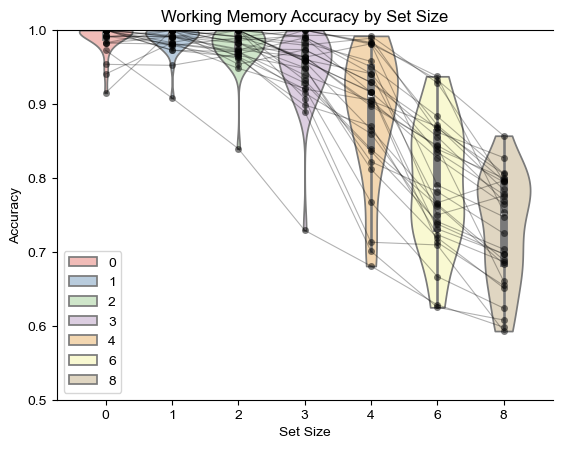

In [9]:
acc_df = (
    pd.DataFrame(WM_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=acc_df, x="Set Size", y="Accuracy", cut=0, hue="Set Size", palette="Pastel1")
plt.title("Working Memory Accuracy by Set Size")
ax.set_ylim(0.5, 1)
sns.despine(right=True, top=False)
# plot strip plots of participants at each set size
sns.stripplot(data=acc_df, x="Set Size", y="Accuracy", color="k", alpha=0.5, jitter=False, size=5)

for sub in acc_df.Subject.unique():
    sub_data = acc_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["Accuracy"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

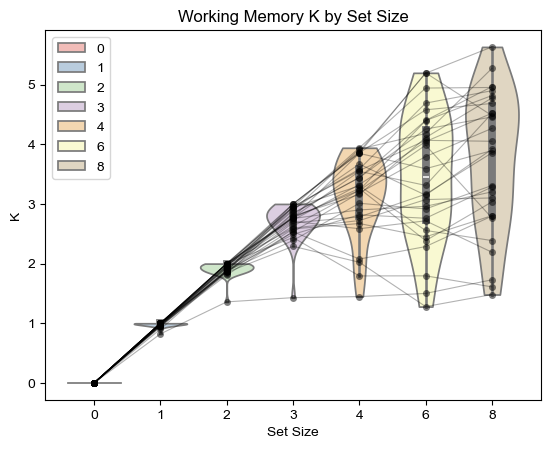

In [10]:
k_df = (
    pd.DataFrame(WM_ks)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="K")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=k_df, x="Set Size", y="K", cut=0, hue="Set Size", palette="Pastel1")
plt.title("Working Memory K by Set Size")
_ = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=0.5, jitter=False, size=5)
# add a line per participant
for sub in k_df.Subject.unique():
    sub_data = k_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["K"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

In [11]:
k_ss_greater_than_3 = k_df[k_df["Set Size"] > 3].groupby("Set Size")["K"].mean()
mean_k_ss_greater_than_3 = k_ss_greater_than_3.mean()
sd_k_ss_greater_than_3 = k_ss_greater_than_3.std()
print(f"Mean K for set sizes greater than 3: {mean_k_ss_greater_than_3:.2f} (SD: {sd_k_ss_greater_than_3:.2f})")

Mean K for set sizes greater than 3: 3.44 (SD: 0.29)


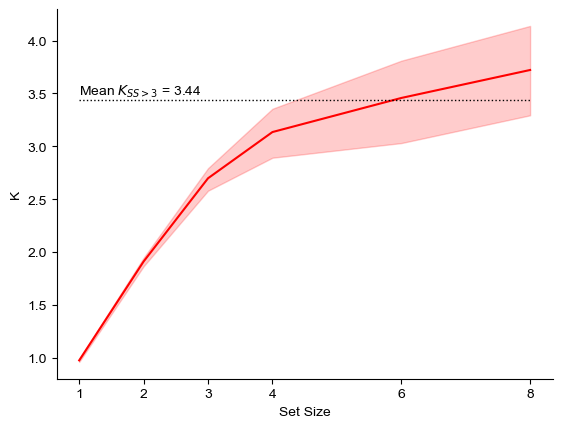

In [12]:
ax = sns.lineplot(data=k_df[k_df["Set Size"] > 0], x="Set Size", y="K", color="red", legend=False)
sns.despine(right=True, top=True)
_ = ax.set_xticks([1, 2, 3, 4, 6, 8])
_ = ax.hlines(y=mean_k_ss_greater_than_3, xmin=1, xmax=8, color="k", linestyle=":", lw=1)
# on the left end, state that the average K for set sizes greater than 3 is around mean_k_ss_greater_than_3
mean_str = f"{mean_k_ss_greater_than_3:.2f}"
_ = ax.text(1, mean_k_ss_greater_than_3 + 0.01, r"Mean $K_{SS>3}$ = " + mean_str, ha="left", va="bottom")
plt.savefig("figures/WM_K_by_set_size.png", dpi=300, bbox_inches="tight", transparent=True)

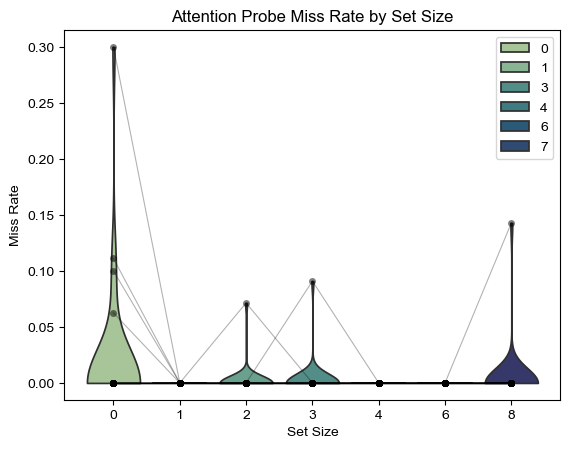

In [13]:
probe_misses_df = (
    pd.DataFrame(Attn_probe_misses)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Miss Rate")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=probe_misses_df, x="Set Size", y="Miss Rate", cut=0, hue="Set Size", palette="crest")
plt.title("Attention Probe Miss Rate by Set Size")
_ = sns.stripplot(data=probe_misses_df, x="Set Size", y="Miss Rate", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_misses_df.Subject.unique():
    sub_data = probe_misses_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["Miss Rate"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )
plt.savefig("figures/Attn_probe_miss_rate_by_set_size.png", dpi=300, bbox_inches="tight", transparent=True)

In [14]:
probe_misses_df[probe_misses_df["Miss Rate"] > 0.05]

,Set Size,Subject,Miss Rate
21,0,04,0.300000
94,3,14,0.090909
98,0,15,0.062500
132,8,20,0.142857
156,2,25,0.071429
161,0,26,0.111111
196,0,35,0.100000


In [15]:
probe_misses_df.groupby("Subject")["Miss Rate"].mean().describe()

count    30.000000
mean      0.004185
std       0.009352
min       0.000000
25%       0.000000
50%       0.000000
75%       0.000000
max       0.042857
Name: Miss Rate, dtype: float64

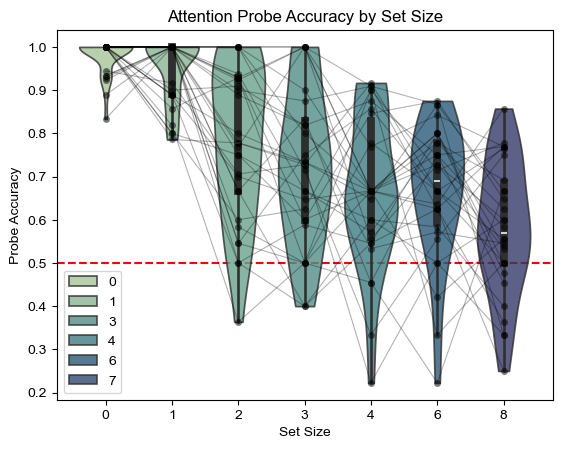

In [16]:
probe_accs_df = (
    pd.DataFrame(Attn_probe_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Probe Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(
    data=probe_accs_df, x="Set Size", y="Probe Accuracy", cut=0, hue="Set Size", palette="crest", alpha=0.8
)
plt.title("Attention Probe Accuracy by Set Size")
_ = sns.stripplot(data=probe_accs_df, x="Set Size", y="Probe Accuracy", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_accs_df.Subject.unique():
    sub_data = probe_accs_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["Probe Accuracy"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )
_ = plt.axhline(0.5, color="r", linestyle="--", label="Chance Level", zorder=-1)

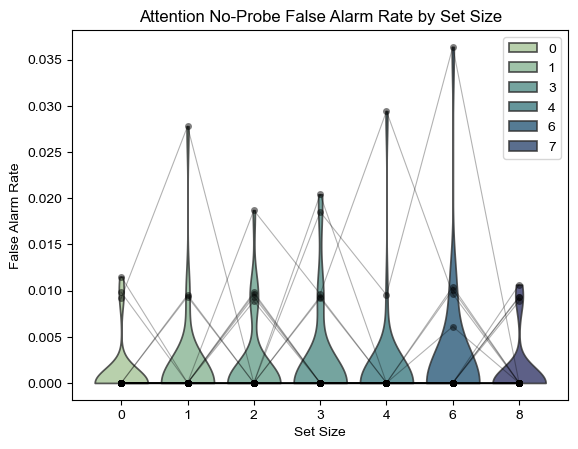

In [17]:
probe_FAs_df = (
    pd.DataFrame(Attn_noProbe_FAs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="False Alarm Rate")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(
    data=probe_FAs_df, x="Set Size", y="False Alarm Rate", cut=0, hue="Set Size", palette="crest", alpha=0.8
)
plt.title("Attention No-Probe False Alarm Rate by Set Size")
_ = sns.stripplot(data=probe_FAs_df, x="Set Size", y="False Alarm Rate", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_FAs_df.Subject.unique():
    sub_data = probe_FAs_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["False Alarm Rate"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )
plt.savefig("figures/behavior_attention_noProbe_FA_by_setsize.png", dpi=300, bbox_inches="tight", transparent=True)

In [18]:
probe_FAs_df.groupby("Subject")["False Alarm Rate"].mean().describe()

count    30.000000
mean      0.001667
std       0.003211
min       0.000000
25%       0.000000
50%       0.001287
75%       0.001370
max       0.014480
Name: False Alarm Rate, dtype: float64

# Change Localization data (for splitting K)

In [19]:
import ast
from collections import defaultdict

In [20]:
change_loc_res = defaultdict(list)
change_loc_files = sorted(glob("../change_localization_data/*.csv"))
for f in change_loc_files:
    sub_df = pd.read_csv(f)
    sub_code = ast.literal_eval(sub_df.loc[1, "response"])["Q0"]
    if "banyan2" in sub_code.lower():
        subid = sub_code.split("_")[1]
        if subid in rejected_subs:
            print(f"Skipping {subid} for change localization analysis, was rejected for behavioral analyses")
            continue

        print(f"Subject ID: {subid}")
        sub_changeLoc_df = sub_df.loc[3:]
        if subid in split_sess_subs.keys():
            second_sess_id = split_sess_subs[subid]
            print(f"concatenating change localization data for {second_sess_id} onto {subid}")
            second_sess_file = f.replace(subid, second_sess_id)
            sub_changeLoc_df_2 = pd.read_csv(second_sess_file).loc[3:]
            sub_changeLoc_df = pd.concat([sub_changeLoc_df, sub_changeLoc_df_2], axis=0).reset_index(drop=True)

        if subid in split_sess_subs.values():
            print(f"Skipping {subid} for change localization analysis, was concatenated onto another subject ID")
            continue

        change_loc_res["subject"].append(subid)
        sub_acc = np.mean(sub_changeLoc_df["accuracy"].astype(float).values)
        change_loc_res["accuracy"].append(sub_acc)
        change_loc_res["K"].append(((sub_acc) * 36 - 6) / 5)  # K formula for change localization with 6 items

Subject ID: 01
Subject ID: 02
Subject ID: 03
Subject ID: 04
Subject ID: 05
Subject ID: 06
Subject ID: 07
Subject ID: 08
Subject ID: 09
Subject ID: 10
Subject ID: 11
Subject ID: 12
Subject ID: 13
Subject ID: 14
Subject ID: 15
Subject ID: 16
Subject ID: 17
Subject ID: 18
Skipping 19 for change localization analysis, was rejected for behavioral analyses
Subject ID: 20
Subject ID: 21
Subject ID: 22
concatenating change localization data for 34 onto 22
Subject ID: 23
Subject ID: 25
Subject ID: 26
Subject ID: 27
Subject ID: 28
Subject ID: 30
Subject ID: 31
Skipping 32 for change localization analysis, was rejected for behavioral analyses
Skipping 33 for change localization analysis, was rejected for behavioral analyses
Subject ID: 34
Skipping 34 for change localization analysis, was concatenated onto another subject ID
Subject ID: 35
Subject ID: 36


In [21]:
change_loc_df = pd.DataFrame(change_loc_res)
median_k = change_loc_df.K.median()
high_k_subs = change_loc_df[change_loc_df.K > median_k]["subject"].values
low_k_subs = change_loc_df[change_loc_df.K <= median_k]["subject"].values
k_sub_map = {sub: "high_K" if sub in high_k_subs else "low_K" for sub in change_loc_df["subject"].values}
k_sub_map

{'01': 'high_K',
 '02': 'low_K',
 '03': 'low_K',
 '04': 'low_K',
 '05': 'low_K',
 '06': 'low_K',
 '07': 'high_K',
 '08': 'low_K',
 '09': 'high_K',
 '10': 'low_K',
 '11': 'low_K',
 '12': 'low_K',
 '13': 'high_K',
 '14': 'low_K',
 '15': 'low_K',
 '16': 'low_K',
 '17': 'low_K',
 '18': 'high_K',
 '20': 'high_K',
 '21': 'high_K',
 '22': 'high_K',
 '23': 'high_K',
 '25': 'low_K',
 '26': 'high_K',
 '27': 'low_K',
 '28': 'low_K',
 '30': 'high_K',
 '31': 'high_K',
 '35': 'high_K',
 '36': 'high_K'}

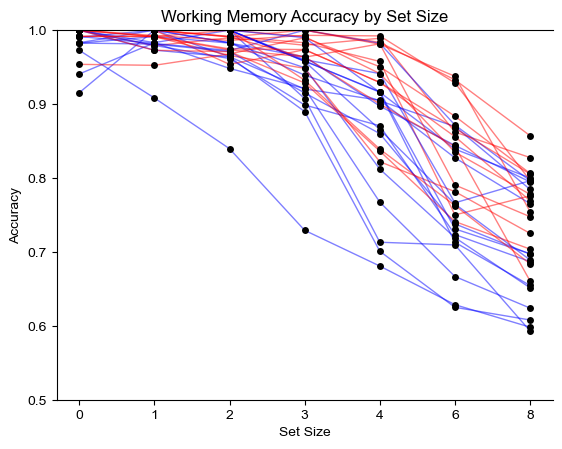

In [22]:
acc_df["K_group"] = acc_df["Subject"].map(k_sub_map)

# plot strip plots of participants at each set size
ax = sns.stripplot(data=acc_df, x="Set Size", y="Accuracy", color="k", alpha=1, jitter=False, size=5)

for sub in wrangl.subs:
    if (sub not in rejected_subs) and (sub not in split_sess_subs.values()):
        sub_data = acc_df.query(f"Subject=='{sub}'")
        plt.plot(
            [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
            sub_data["Accuracy"],
            color="red" if k_sub_map[sub] == "high_K" else "blue",
            alpha=0.5,
            linewidth=1,
        )

plt.title("Working Memory Accuracy by Set Size")
ax.set_ylim(0.5, 1)
sns.despine(right=True, top=False)
plt.show()

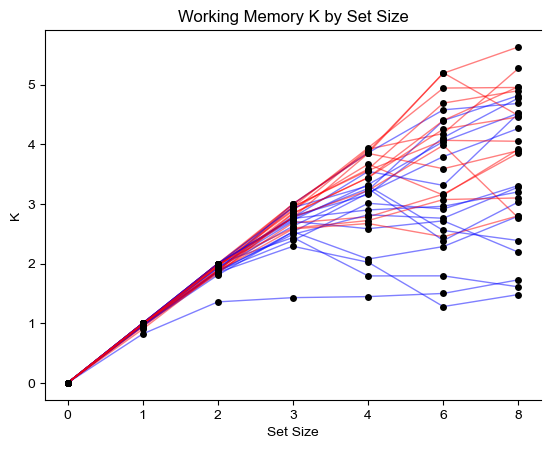

In [23]:
ax = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=1, jitter=False, size=5)

for sub in wrangl.subs:
    if (sub not in rejected_subs) and (sub not in split_sess_subs.values()):
        sub_data = k_df.query(f"Subject=='{sub}'")
        plt.plot(
            [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
            sub_data["K"],
            color="red" if k_sub_map[sub] == "high_K" else "blue",
            alpha=0.5,
            linewidth=1,
        )

plt.title("Working Memory K by Set Size")
sns.despine(right=True, top=False)
plt.show()

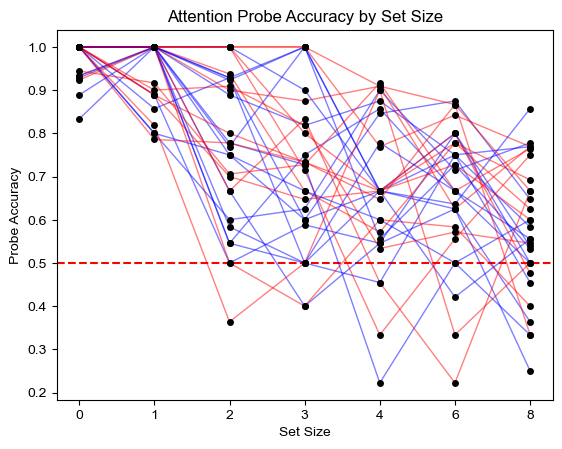

In [24]:
ax = sns.stripplot(data=probe_accs_df, x="Set Size", y="Probe Accuracy", color="k", alpha=1, jitter=False, size=5)
for sub in wrangl.subs:
    if (sub not in rejected_subs) and (sub not in split_sess_subs.values()):
        sub_data = probe_accs_df.query(f"Subject=='{sub}'")
        plt.plot(
            [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
            sub_data["Probe Accuracy"],
            color="red" if k_sub_map[sub] == "high_K" else "blue",
            alpha=0.5,
            linewidth=1,
        )
_ = plt.axhline(0.5, color="r", linestyle="--", label="Chance Level", zorder=-1)
plt.title("Attention Probe Accuracy by Set Size")
plt.show()

# Save out rejected subs

In [ ]:
import json

with open("rejected_subs.json", "w") as f:
    json.dump(rejected_subs, f)
rejected_subs

['19', '32', '33']

# Get the subject demographics

In [27]:
info_files = sorted(glob("../raw_data/*/*_info.csv"))
info_files

['../raw_data/01/01_info.csv',
 '../raw_data/02/02_info.csv',
 '../raw_data/03/03_info.csv',
 '../raw_data/04/04_info.csv',
 '../raw_data/05/05_info.csv',
 '../raw_data/06/06_info.csv',
 '../raw_data/07/07_info.csv',
 '../raw_data/08/08_info.csv',
 '../raw_data/09/09_info.csv',
 '../raw_data/10/10_info.csv',
 '../raw_data/11/11_info.csv',
 '../raw_data/12/12_info.csv',
 '../raw_data/13/13_info.csv',
 '../raw_data/14/14_info.csv',
 '../raw_data/15/15_info.csv',
 '../raw_data/16/16_info.csv',
 '../raw_data/17/17_info.csv',
 '../raw_data/18/18_info.csv',
 '../raw_data/19/19_info.csv',
 '../raw_data/20/20_info.csv',
 '../raw_data/21/21_info.csv',
 '../raw_data/22/22_info.csv',
 '../raw_data/23/23_info.csv',
 '../raw_data/25/25_info.csv',
 '../raw_data/26/26_info.csv',
 '../raw_data/27/27_info.csv',
 '../raw_data/28/28_info.csv',
 '../raw_data/30/30_info.csv',
 '../raw_data/31/31_info.csv',
 '../raw_data/32/32_info.csv',
 '../raw_data/33/33_info.csv',
 '../raw_data/34/34_info.csv',
 '../raw

In [ ]:
info_files = sorted(glob("../raw_data/*/*_info.csv"))
exp_info = pd.DataFrame()
for ifile in info_files:
    subid = ifile.split("/")[-2]
    sub_info = pd.read_csv(ifile)
    sub_info["subid"] = subid
    exp_info = pd.concat([exp_info, sub_info], ignore_index=True)

# drop repeated unique IDs, which are just the same subject who came back for a second session
exp_info = exp_info.drop_duplicates(subset=["Unique ID"], keep="first").reset_index(drop=True)
del exp_info["Unique ID"]  # delete the Unique IDs to preserve anonymity
exp_info

,Subject,Age,Gender,subid
0,1,33,F,01
1,2,22,m,02
2,3,24,F,03
3,4,30,m,04
4,5,21,f,05
5,6,28,f,06
6,7,32,f,07
7,8,24,f,08
8,9,20,m,09
9,10,30,F,10


In [29]:
exp_info.Age.describe()

count    33.000000
mean     24.121212
std       4.136405
min      18.000000
25%      21.000000
50%      24.000000
75%      26.000000
max      33.000000
Name: Age, dtype: float64

In [30]:
clean_string = lambda s: s.strip().lower()[0]
exp_info["Gender_clean"] = exp_info.Gender.astype(str).apply(clean_string)
exp_info.Gender_clean.value_counts()

Gender_clean
f    21
m    10
n     2
Name: count, dtype: int64

In [31]:
rejected_subs

['19', '32', '33']

In [32]:
exp_info_keep = exp_info[~exp_info.subid.isin(rejected_subs)]
exp_info_keep

,Subject,Age,Gender,subid,Gender_clean
0,1,33,F,01,f
1,2,22,m,02,m
2,3,24,F,03,f
3,4,30,m,04,m
4,5,21,f,05,f
5,6,28,f,06,f
6,7,32,f,07,f
7,8,24,f,08,f
8,9,20,m,09,m
9,10,30,F,10,f


In [33]:
exp_info_keep.Age.describe()

count    30.000000
mean     24.333333
std       4.179864
min      18.000000
25%      21.000000
50%      24.000000
75%      26.750000
max      33.000000
Name: Age, dtype: float64

In [34]:
exp_info_keep.Gender_clean.value_counts()

Gender_clean
f    21
m     8
n     1
Name: count, dtype: int64

# compare the overlap of subjects in the 2 experiments

In [35]:
info_files = sorted(glob("../raw_data/*/*_info.csv"))
exp_info = pd.DataFrame()
for ifile in info_files:
    subid = ifile.split("/")[-2]
    sub_info = pd.read_csv(ifile)
    exp_info = pd.concat([exp_info, sub_info], ignore_index=True)
exp2_unique_ids = exp_info["Unique ID"]

In [36]:
exp1_info_files = sorted(glob("../../Experiment 1/raw_data/*/*_info.csv"))
exp1_info = pd.DataFrame()
for ifile in exp1_info_files:
    subid = ifile.split("/")[-2]
    sub_info = pd.read_csv(ifile)
    exp1_info = pd.concat([exp1_info, sub_info], ignore_index=True)
exp1_unique_ids = exp1_info["Unique ID"]

In [37]:
len(set(exp1_unique_ids))

34

In [38]:
len(set(exp2_unique_ids))

33

In [39]:
len(set(exp1_unique_ids).intersection(set(exp2_unique_ids)))

4